# GMM
## Uma breve revisão
Conforme discutido em sala de aula, a técnica assume que o conjunto de dados no qual eu quero categorizar foi gerado por um conjunto de gaussianas de parâmetros $\theta = \{\theta_1,\theta_2,\dots,\theta_K\}$. O modelo, então, teria o seguinte comportamento:
- Para cada "rodada", uma das $K$ gaussianas são sorteadas, com probabilidade da $k$-ésima gaussiana ser sorteada dada por $\pi_k$
- A $k$-ésima gaussiana sorteia uma observação, com probabilidade de sortear uma observação desejada $x_n$ dada pela gaussiana ($\mathcal{N}(x_n|\theta_k)$)
> O pertencimento à um grupo, nesse caso, é a probabilidade da $k$-ésima gaussiana de ter gerado um dado
 <center>
<img src="figs/GMM_introduction.png" alt="drawing" width="50%" />
 </center>


In [ ]:
from sklearn.datasets import make_blobs
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from ykk import GMM


## Determinando os parâmetros
Utilizamos o teorema de bayes para inverter o problema e utilizamos o algoritmo *Expectation-Maximization* para ajustar o meu modelo ao meu conjunto de dados. As principais equações desse procedimento é dada por:
- A responsabilidade do cluster $k$ pela $n$-ésima observação:
$$
\gamma_{nk} = \frac{\mathcal{N}(x_n|\theta_k)\pi_k}{\Sigma_{k=1}^K \pi_k \mathcal{N}(x_n|\theta_k)},
$$
- A probabilidade do meu modelo ter gerado meus dados:
$$
\log \ell(\theta)= \sum_{n=1}^{N}\log\sum_{k=1}^{K}\pi_k\mathcal{N}(x_n|\theta_k).
$$
- A solução do problema:
$$\hat{\theta} = \arg \max_{\theta}\left\{\log \ell(\theta)\right\}.$$

## Obtendo $\hat{\theta}$: implementando o Expectation-Maximization
A implementação é fortemente baseada em `sklearn.mixture.GaussianMixture`

### Gerando um conjunto de dados para visualização

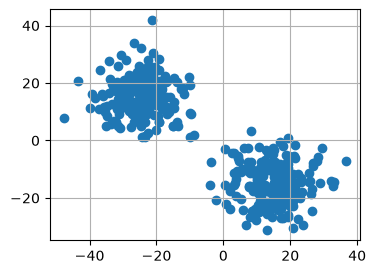

In [2]:
X, _ = make_blobs(n_samples=[200,200],
                  n_features=2, 
                  centers=[[-25,15],
                           [15,-15]], cluster_std=7, random_state=42)
plt.figure(figsize=(4, 3))
plt.scatter(*X[:].T.tolist())
plt.grid()

### Passo 1: Inicializando o GMM
Para inicializar, utilizamos o $k$-means, permitindo estimar um conjunto de parâmetros iniciais $\pi_k$, $\theta^{(0)}_k = (\mu_k,\Sigma_k)$

``` python
def _initialize(self, X,):
    n_samples, n_dims = X.shape
    centroids,labels,_=cluster.k_means(X = X,
                                   n_clusters = self.K,
                                   n_init=1
                                   )
    self.means_ = centroids

    self.pi_ = np.zeros([self.K, 1])
    self.covariances_ = np.zeros([self.K, n_dims, n_dims])
    for k in range(self.K):
        self.pi_[k] = labels[ labels == k ].shape[0]/n_samples
        self.covariances_[k,:] = np.cov( X[labels == k].T )
```

In [ ]:
gmm = GMM(K=2, 
          max_iter=100, 
          random_state=42,
          reg=1E-6
          )
gmm._initialize(X=X,)

### Passo 2: Expectation
Avaliar a responsabilidade de cada cluster pela $n$-ésima observação
$$
\gamma_{nk} = \frac{\mathcal{N}(x_n|\theta_k)\pi_k}{\Sigma_{k=1}^K \pi_k \mathcal{N}(x_n|\theta_k)},
$$
``` python
def _expectation(self, X):
    n_samples = X.shape[0]
    gamma = np.zeros((n_samples, self.K))

    for k in range(self.K):
        gamma[:, k] = self.pi_[k] * self._gaussian(X, self.means_[k], self.covariances_[k])
    
    gamma /= gamma.sum(axis=1, keepdims=True)
    return gamma
```

### Passo 3: Maximization
O novo conjunto de parâmetros soluciona a equação
$$
\arg\max_\theta \sum_{n=1}^N \sum_{k=1}^K \gamma_{nk}^{(t)} \log\big[\pi_k\,\mathcal{N}(x_n|\theta_k)\big]
$$
isso ocorre quando
$$
\pi_k = \frac{\sum_{n=1}^N \gamma_{nk}}{N},\Sigma_k = \frac{\sum_{n=1}^N \gamma_{nk}(x_n-\mu_k)(x_n-\mu_k)^\mathrm{T}}{\sum_{n=1}^{N}\gamma_{nk}}, \mu_k = \frac{\sum_{n=1}^N \gamma_{nk}x_n}{\sum_{n=1}^N \gamma_{nk}}.
$$

``` python
def _maximization(self, X, gamma):
    n_samples, n_dims = X.shape
    gamma_k = gamma.sum(axis=0)
    self.pi_ = gamma_k / n_samples
    self.means_ = (gamma.T @ X) / gamma_k[:, np.newaxis]
    for k in range(self.K):
        deviation = X - self.means_[k] # Desvio (da média)
        self.covariances_[k] = ((gamma[:, k] * deviation.T) @ deviation) / gamma_k[k]

```

In [4]:
ll_old = -np.inf
for i in range(gmm.max_iter):
    resp = gmm._expectation(X)      # Avalia gamma_nk em todas as observações
    gmm._maximization(X, resp)      # Estima parâmetros que maximizem o log-likelihood
    ll = gmm._log_l(X)              # Avalia log-likelihood da iteração
    probs = gmm.predict_proba(X)    # Basicamente um wrapper de gmm._expectation()
    if abs(ll-ll_old) <= gmm.tol: 
        print(f'convergiu na iteração {i}')
        break
    ll_old = ll

convergiu na iteração 1


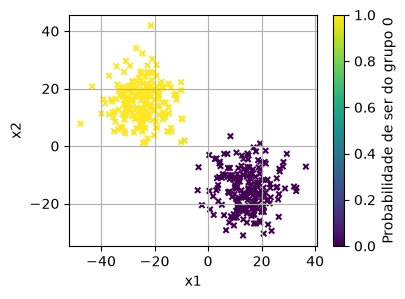

In [5]:
fig, ax = plt.subplots(figsize=(4, 3))

artist= ax.scatter(*X.T.tolist(), c=probs[:,0],
                    cmap='viridis', s=15, alpha=1,marker='x')
ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.colorbar(artist,label='Probabilidade de ser do grupo 0')
plt.grid()

## Dificultando um pouco mais
O conjunto de dados anterior foi muito fácil, podemos criar dados menos separados para observar a variação continua entre clusters. 

Note que: apesar de `make_blobs` receber multiplos argumentos, esses argumentos buscam representar apenas **dois clusters**. Os demais clusters, então, representam apenas adição de **ruído** ao conjunto de dados.

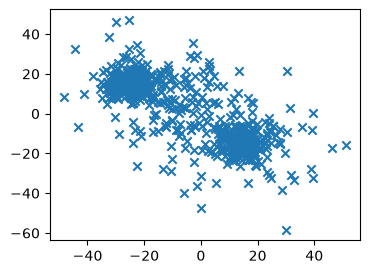

In [6]:
X, _ = make_blobs(n_samples=[200,200,100,50,50],
                  n_features=2, 
                  centers=[[-25,15],
                           [15,-15],
                           [-5,0],
                           [-25,15],
                           [15,-15],], cluster_std=[5,5,12,15,15], random_state=42)
plt.figure(figsize=(4, 3))
plt.scatter(*X.T.tolist(),marker='x');

Repetimos o *Expectation-Maximization*, porém salvando o resultado de cada iteração para visualizarmos como o algoritmo se comporta.
> Nota: idealmente, repetimos o experimento várias vezes e salvamos o resultado com maior $\log l(\theta)$. Para simplificação, estamos repetindo uma única vez.

In [17]:
gmm = GMM(n_components=2, max_iter=100, random_state=42,reg=1E-6)
gmm._initialize(X=X,)
frames = []

ll_old = -np.inf
for i in range(gmm.max_iter):
    resp = gmm._expectation(X)
    gmm._maximization(X, resp)
    ll = gmm._log_l(X)
    probs = gmm.predict_proba(X)
    
    # Salvando os dados da animação
    frames.append({
        'X': X.copy(),
        'probs0': probs[:, 0].copy(),
        'means': gmm.means_.copy(),
        'll': ll
    })
    if abs(ll-ll_old) <= gmm.tol:
        print(f'convergiu na iteração {i}')
        break
    ll_old = ll

convergiu na iteração 66


#### Visualizando o resultado
- Assim como no $k$-means, os centróides tendem a estabilizar com o passar das iterações
- As principais variações ocorrem nas fronteiras
- O $\log \ell(\theta)$ aumenta até estabilizar em um máximo local

In [20]:
fig, ax = plt.subplots(figsize=(4, 3.5))
def update(frame_idx):
    ax.clear()
    f = frames[frame_idx]
    ax.scatter(*f['X'].T.tolist(), c=f['probs0'],
               cmap='viridis', s=30, alpha=0.7)
    ax.scatter(*f['means'].T.tolist(),
               c='red', marker='x', s=200)
    ax.set_title(f"Iteração {frame_idx + 1} — $\\log \\ell(\\theta^{{({frame_idx+1})}})$ = {f['ll']:.3f}")
    ax.set_xlabel("x1"); ax.set_ylabel("x2")
anim = FuncAnimation(fig, update, frames=len(frames), interval=(1/15)*1E3, repeat=True)
plt.close(fig)
HTML(anim.to_jshtml())

## Usando o sklearn
Conforme mencionado anteriormente, a implementação anterior é fortemente baseada em `sklearn.mixture.GaussianMixture`. Para fins de completude, mostro como realizar a mesma análise utilizando o scikit-learn.

In [23]:
from sklearn.mixture import GaussianMixture
gmm_sk = GaussianMixture(n_components=2,
                        covariance_type='full',
                        tol=1E-4,
                        reg_covar=1E-6,
                        max_iter=100,
                        n_init=100,
                        random_state=42
                        )
gmm_sk.fit(X)
labels = gmm_sk.predict_proba(X)

Text(0, 0.5, 'x2')

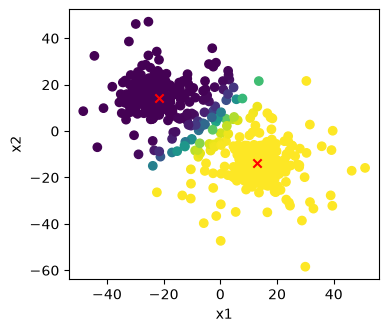

In [27]:
plt.figure(figsize=(4, 3.5))
plt.scatter(*X.T.tolist(),c=labels[:,0])
plt.scatter(*gmm_sk.means_.T.tolist(),marker='x',c='red')
ax = plt.gca()
ax.set_xlabel("x1"); ax.set_ylabel("x2")
